<a href="https://colab.research.google.com/github/rmarharyta/machinelearning/blob/main/%D0%9B%D0%A0_7_%D0%9B%D0%BE%D0%B3_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_%D0%B2%D1%80%D1%8F%D1%82%D1%83%D0%B2%D0%B0%D1%82%D0%B8_%D0%BF%D1%80%D0%B8%D0%BD%D1%86%D0%B5%D1%81%D1%83_26_%D0%A0%D1%83%D0%B1%D0%BB%D0%B5%D0%BD%D0%BA%D0%BE_4_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

**Автор роботи: студентка групи ФІТ 4-10 Рубленко Маргарита Віталіївна**

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("unmoved/cure-the-princess")

print("Path to dataset files:", path)

100%|██████████| 49.2k/49.2k [00:00<00:00, 170kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/unmoved/cure-the-princess/versions/1


In [ ]:
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))

Using Colab cache for faster access to the 'cure-the-princess' dataset.


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [ ]:
df.head()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [ ]:
df.shape

(2338, 14)

In [ ]:
df.isnull().sum()

,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Під час первинного аналізу було встановлено, що датасет містить 2338 спостережень і 14 стовпців. Пропущених значень і дублікатів не виявлено. Дані містять 13 числових ознак магічних інгредієнтів та цільову змінну Cured. За результатами описової статистики ознаки мають різні діапазони значень, тому перед навчанням моделі доцільно виконати стандартизацію. Цільова змінна має два класи, які розподілені приблизно порівну.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [ ]:
X = df.drop("Cured", axis=1)
y = df["Cured"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (1870, 13)
Тестова вибірка: (468, 13)


### 5. Баланс класів на навчальній вибірці

Кількість спостережень кожного класу:
Cured
0    946
1    924
Name: count, dtype: int64


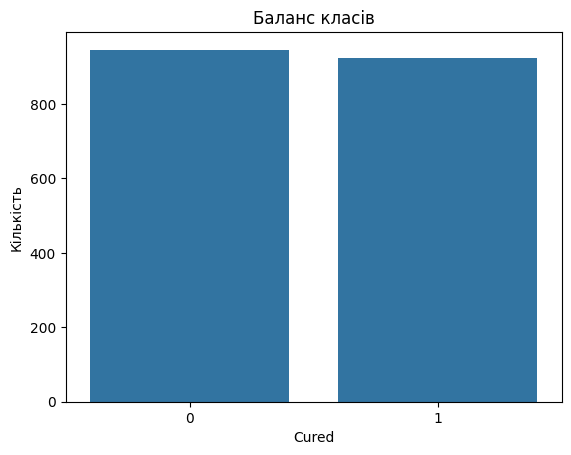

In [ ]:
print("Кількість спостережень кожного класу:")
print(y_train.value_counts())

sns.countplot(x=y_train)
plt.title("Баланс класів")
plt.xlabel("Cured")
plt.ylabel("Кількість")
plt.show()

**Висновок:**  
За результатами аналізу встановлено, що класи є збалансованими. Клас 0 містить 946 спостережень, а клас 1 — 924, тому різниця між ними незначна. Такий розподіл є сприятливим для навчання моделі, оскільки вона не матиме значного зміщення в бік одного класу.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

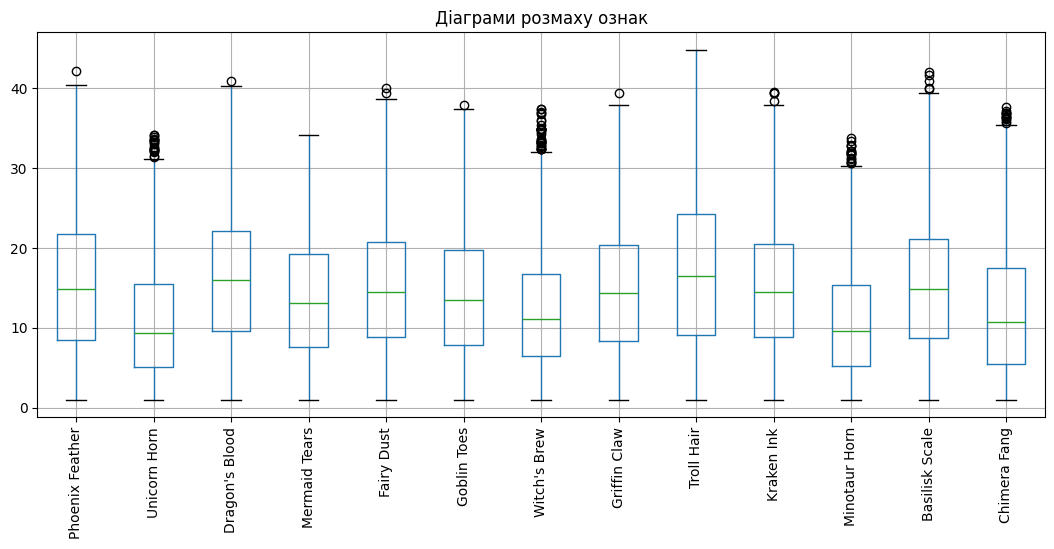

Кількість викидів:
Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


In [ ]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title("Діаграми розмаху ознак")
plt.show()

q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

outliers = (
    (X_train < (q1 - 1.5 * iqr)) |
    (X_train > (q3 + 1.5 * iqr)))

print("Кількість викидів:")
print(outliers.sum().sort_values(ascending=False))

**Висновок про викиди:**  
У ході аналізу було виявлено потенційні викиди в кількох ознаках. Найбільше їх спостерігається у Witch's Brew (33), Unicorn Horn (20) та Minotaur Horn (18). В інших ознаках кількість викидів значно менша або вони відсутні.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

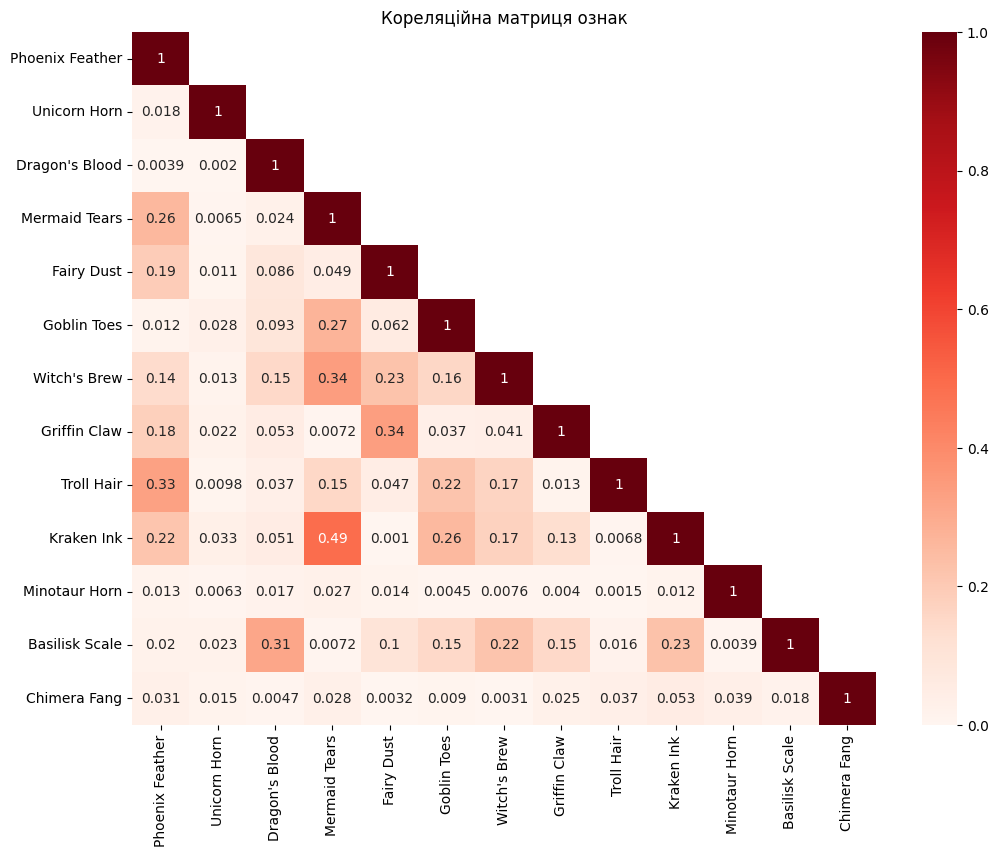

Кореляція ознак із Cured:
Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Basilisk Scale    -0.042277
Kraken Ink        -0.026598
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Griffin Claw      -0.005871
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Name: Cured, dtype: float64


In [ ]:
mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype=bool), k=1)

plt.figure(figsize=(12, 9))
sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    cmap="Reds",
    vmin=0,
    vmax=1)
plt.title("Кореляційна матриця ознак")
plt.show()

train_data = pd.concat([X_train, y_train], axis=1)

correlation = train_data.corr()["Cured"].drop("Cured")

print("Кореляція ознак із Cured:")
print(correlation.reindex(correlation.abs().sort_values(ascending=False).index))

**Висновок про кореляції:**  
За результатами кореляційного аналізу встановлено, що найбільший зв’язок між ознаками спостерігається у Mermaid Tears і Kraken Ink (0.49), а також Fairy Dust і Griffin Claw (0.34). Найсильнішу позитивну кореляцію з цільовою змінною Cured мають Troll Hair (0.49) та Witch's Brew (0.25).

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Навчальні дані:", X_train_scaled.shape)
print("Тестові дані:", X_test_scaled.shape)

Навчальні дані: (1870, 13)
Тестові дані: (468, 13)


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

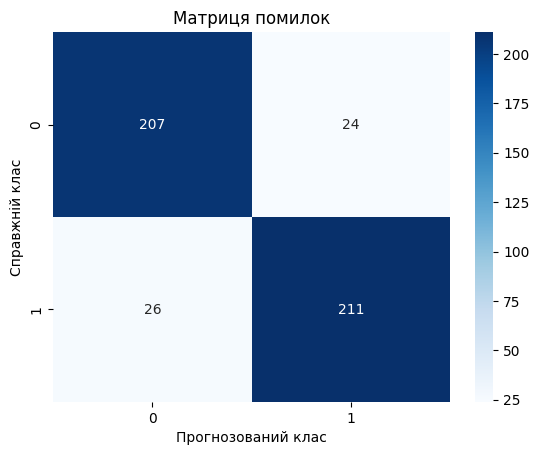

,Справжній клас,Прогнозований клас
55,0,1
63,0,0
33,1,0
297,1,1
72,1,1
228,0,0
209,1,1
9,1,1
428,0,0
231,1,1


In [ ]:
conf = confusion_matrix(y_test, y_pred)

sns.heatmap(conf, annot=True, fmt="d", cmap="Blues")
plt.title("Матриця помилок")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.show()

results = pd.DataFrame({
    "Справжній клас": y_test.to_numpy(),
    "Прогнозований клас": y_pred})

display(results.sample(10, random_state=42))

**Висновок щодо якості логістичної регресії:**  
За результатами матриці помилок модель правильно класифікувала більшість спостережень. Було допущено 26 хибнонегативних і 24 хибнопозитивні помилки, тобто хибнонегативних трохи більше.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "solver": ["liblinear", "lbfgs"],
    "max_iter": [500, 1000]}

param_dist = {
    "C": [0.01, 0.1, 1, 10],
    "solver": ["liblinear", "lbfgs"],
    "max_iter": [500, 1000]}

grid_search = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=3,
    scoring="accuracy")

grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри GridSearchCV:")
print(grid_search.best_params_)
print("Найкраща оцінка CV:", grid_search.best_score_)

random_search = RandomizedSearchCV(
    LogisticRegression(),
    param_dist,
    n_iter=10,
    cv=3,
    scoring="accuracy",
    random_state=42)

random_search.fit(X_train_scaled, y_train)

print("\nНайкращі параметри RandomizedSearchCV:")
print(random_search.best_params_)
print("Найкраща оцінка CV:", random_search.best_score_)

# Вибираємо модель за найкращою оцінкою CV
if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
else:
    best_model = random_search.best_estimator_

best_pred = best_model.predict(X_test_scaled)

print("\nAccuracy після підбору:",
      accuracy_score(y_test, best_pred))

print(classification_report(y_test, best_pred))

Найкращі параметри GridSearchCV:
{'C': 10, 'max_iter': 500, 'solver': 'liblinear'}
Найкраща оцінка CV: 0.8673927508197171

Найкращі параметри RandomizedSearchCV:
{'solver': 'liblinear', 'max_iter': 1000, 'C': 10}
Найкраща оцінка CV: 0.8673927508197171

Accuracy після підбору: 0.8931623931623932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Обидва методи пошуку обрали однакові значення параметрів C=10 та solver='liblinear', але різні значення max_iter. Після підбору параметрів модель досягла точності близько 89,3%. Порівняно з базовою логістичною регресією суттєвого покращення не відбулося.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [ ]:
log_model = best_model
svm_model = SVC()
tree_model = DecisionTreeClassifier(random_state=42)

models = {
    "Logistic Regression": log_model,
    "SVM": svm_model,
    "Decision Tree": tree_model
}

results_models = []

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    predictions = clf.predict(X_test_scaled)

    results_models.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)})

comparison = pd.DataFrame(results_models)

display(comparison.round(3))

best = comparison.sort_values(
    ["F1-score", "Accuracy"], ascending=False).iloc[0]

print("Найкраща модель:", best["Модель"])

,Модель,Accuracy,F1-score
0,Logistic Regression,0.893,0.894
1,SVM,0.959,0.960
2,Decision Tree,0.865,0.866


Найкраща модель: SVM


### 13. Висновки до лабораторної роботи

У ході лабораторної роботи було досліджено датасет Cure the Princess для задачі бінарної класифікації. Під час первинного аналізу не було виявлено пропусків і дублікатів, а класи виявилися приблизно збалансованими. Дослідження показало наявність викидів у деяких ознаках, а найбільший зв'язок із цільовою змінною мали Troll Hair та Witch's Brew. Після стандартизації даних було навчено модель логістичної регресії, яка показала хорошу точність класифікації. Підбір гіперпараметрів за допомогою GridSearchCV та RandomizedSearchCV не дав суттєвого покращення результатів. Також було проведено порівняння логістичної регресії, SVM і дерева рішень. Найкращою моделлю виявився SVM, який продемонстрував найвищі показники Accuracy та F1-score. Отже, робота показала важливість аналізу даних, налаштування моделей та порівняння різних алгоритмів машинного навчання.
